In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
import seaborn as sns 

import os,csv
import torch
from torch import nn
import torch.nn.functional as F
from pathlib import Path
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import r2_score
from pprint import pprint

from pn.CNN3D import *
import pn.p5_utils as p5u

# Style Decisions

9


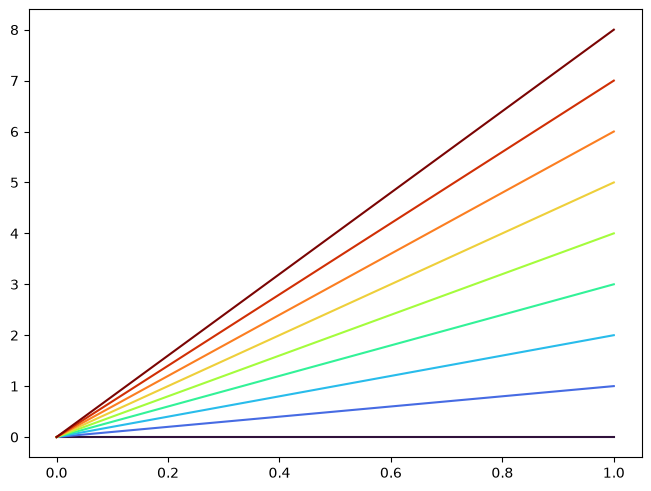

In [2]:
# pick a colormap
cmap = plt.get_cmap('turbo')
color_list = cmap(np.linspace(0,1,9))
fig, ax = plt.subplots(layout='constrained')

for i, color in enumerate(color_list):
    ax.plot([0, i], color=color_list[i])

print(len(color_list))
color_list = color_list[1:]

# P1 (NSR-004-002)

In [2]:
# load data
config = Config(2)
train_loader, valid_loader, test_loader = get_dataloaders(config)

Using default channels, all inbound electrodes will be included.
Loading Train Files...
D:\Becca\Data\PN_preprocessed\NSR-004-002\Training block 1_green__loc4_7_1742409770184_250319_144250_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-004-002\Training block 2_green__loc8_1_1742410047212_250319_144727_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-004-002\Training block 3_green__loc4_3_1742410337516_250319_145217_hga.pt
Loading Val Files...
D:\Becca\Data\PN_preprocessed\NSR-004-002\Validation block_green_loc8_2_1742410614837_250319_145654_hga.pt
Loading Test Files...
D:\Becca\Data\PN_preprocessed\NSR-004-002\Validation block_green_loc8_2_1742410614837_250319_145654_hga.pt


In [3]:
# make model
model = CNN2D_LSTM(config)
optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay)
criterion = torch.nn.MSELoss(reduction='sum')

# train
CNN3D_train(model, optimizer, criterion, config, train_loader, valid_loader)

Epoch 0/30: train:13.967391207056531  val:17.03083062171936
Epoch 1/30: train:5.370430302821983  val:14.393604135513305
Epoch 2/30: train:3.1823947808500064  val:13.539971137046814
Epoch 3/30: train:2.186992249498933  val:11.781631422042846
Epoch 4/30: train:1.7497830327789663  val:11.15773937702179
Epoch 5/30: train:1.288646992485402  val:11.306148099899293
Epoch 6/30: train:1.0940487103189451  val:11.504598760604859
Epoch 7/30: train:0.8951651793667825  val:11.160981726646423
Epoch 8/30: train:0.7779065328886954  val:11.07893989086151
Epoch 9/30: train:0.6873133630191876  val:11.090824282169342
Epoch 10/30: train:0.6411228379455663  val:10.807822704315186
Epoch 11/30: train:0.5543643390223131  val:10.942625260353088
Epoch 12/30: train:0.49863513331797166  val:10.36095941066742
Epoch 13/30: train:0.4552374846159907  val:10.231344079971313
Epoch 14/30: train:0.4201146585045982  val:10.227745747566223
Epoch 15/30: train:0.39076605420243943  val:10.588263547420501
Epoch 16/30: train:0.38

In [4]:
tgts2, preds2 = CNN3D_predict(model, test_loader)

In [6]:
offline_2 = r2_score(tgts2,preds2)
print(f"R2 {offline_2}")

error = np.linalg.norm(tgts2 - preds2,axis=1)
se = error**2
mse = np.mean(se)

print("% mse {mse/2}")


R2 0.6969833374023438
% mse {mse/2}


# P2 (NSR-004-003)

In [11]:
# load data
config = Config(3)
train_loader, valid_loader, test_loader = get_dataloaders(config)

Using default channels, all inbound electrodes will be included.
Loading Train Files...
D:\Becca\Data\PN_preprocessed\NSR-004-003\Training block 1_FIH0050blue__loc4_6_1744227575794_250409_153935_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-004-003\Training block 2_FIH0050blue__loc8_2_1744227839734_250409_154359_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-004-003\Training block 3_FIH0050blue__loc4_2_1744228097783_250409_154817_hga.pt
Loading Val Files...
D:\Becca\Data\PN_preprocessed\NSR-004-003\Validation block_FIH0050blue_loc8_3_1744228487511_250409_155447_hga.pt
Loading Test Files...
D:\Becca\Data\PN_preprocessed\NSR-004-003\Validation block_FIH0050blue_loc8_3_1744228487511_250409_155447_hga.pt


In [19]:
# make model
model = CNN2D_LSTM(config)
optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay)
criterion = torch.nn.MSELoss(reduction='sum')

# train
CNN3D_train(model, optimizer, criterion, config, train_loader, valid_loader)

Epoch 0/30: train:9.094603008237378  val:9.04616446495056
Epoch 1/30: train:2.13510649574214  val:5.823624849319458
Epoch 2/30: train:1.217019408941269  val:4.762744927406311
Epoch 3/30: train:0.9019152480980446  val:5.067026925086975
Epoch 4/30: train:0.73465026195707  val:5.568399441242218
Epoch 5/30: train:0.5681066841914736  val:4.482926166057586
Epoch 6/30: train:0.4666563565361089  val:4.13794093132019
Epoch 7/30: train:0.4289623699311552  val:4.444597923755646
Epoch 8/30: train:0.37048207197723715  val:3.825340461730957
Epoch 9/30: train:0.3192245669919869  val:3.8168009996414183
Epoch 10/30: train:0.28426288813352585  val:4.07140462398529
Epoch 11/30: train:0.24995480375043277  val:3.871688985824585
Epoch 12/30: train:0.23999712365711556  val:3.7349937677383425
Epoch 13/30: train:0.22445329561315733  val:3.6364206790924074
Epoch 14/30: train:0.2135160279556595  val:3.531135380268097
Epoch 15/30: train:0.20314595925396886  val:3.319531571865082
Epoch 16/30: train:0.1832289031610

In [20]:
tgts3, preds3 = CNN3D_predict(model, test_loader)

offline_3 = r2_score(tgts3,preds3)
print(f"R2 {offline_3}")

error = np.linalg.norm(tgts3 - preds3,axis=1)
se = error**2
mse = np.mean(se)

print(f"% mse {mse/2}")


R2 0.8097105622291565
% mse 0.023723799735307693


# P3

In [21]:
# load data
config = Config(4)
train_loader, valid_loader, test_loader = get_dataloaders(config)

Using default channels, all inbound electrodes will be included.
Loading Train Files...
D:\Becca\Data\PN_preprocessed\NSR-004-004\center-out-easy-block1_FIH0068__1_1753286802143_250723_160642_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-004-004\center-out-easy-block2_FIH0068__1_1753287064855_250723_161104_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-004-004\center-out-easy-block3_FIH0068__3_1753287429688_250723_161709_hga.pt
Loading Val Files...
D:\Becca\Data\PN_preprocessed\NSR-004-004\center-out-easy-block4_FIH0068__1_1753288012531_250723_162652_hga.pt
Loading Test Files...
D:\Becca\Data\PN_preprocessed\NSR-004-004\center-out-easy-block4_FIH0068__1_1753288012531_250723_162652_hga.pt


In [22]:
# make model
model = CNN2D_LSTM(config)
optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay)
criterion = torch.nn.MSELoss(reduction='sum')

# train
CNN3D_train(model, optimizer, criterion, config, train_loader, valid_loader)

Epoch 0/50: train:4.066779742165218  val:3.9646476223355247
Epoch 1/50: train:2.483401614522177  val:3.354604732422602
Epoch 2/50: train:0.8117245918228513  val:2.7903040874572027
Epoch 3/50: train:0.45010017449893647  val:2.5265332006272816
Epoch 4/50: train:0.3414835858912695  val:2.2178654841014316
Epoch 5/50: train:0.270184976713998  val:2.139055706205822
Epoch 6/50: train:0.23283870991260286  val:2.1065399675142196
Epoch 7/50: train:0.19284181202214862  val:1.920196839741298
Epoch 8/50: train:0.19067090418603685  val:1.9183335162344433
Epoch 9/50: train:0.1787464058115369  val:1.973084228379386
Epoch 10/50: train:0.155469348506322  val:1.904654553958348
Epoch 11/50: train:0.1406199854044687  val:1.956153773126148
Epoch 12/50: train:0.1405926373979402  val:1.7833223257746016
Epoch 13/50: train:0.12112524774339464  val:1.8533987261000133
Epoch 14/50: train:0.11657144744244832  val:1.785599941299075
Epoch 15/50: train:0.1038904796753611  val:1.765564793632144
Epoch 16/50: train:0.103

In [27]:
tgts4, preds4 = CNN3D_predict(model, test_loader)

offline_4 = r2_score(tgts4,preds4)
print(f"R2 {offline_4}")

error = np.linalg.norm(tgts3 - preds3,axis=1)
se = error**2
pmse4 = np.mean(se)/2

print(f"% mse {pmse4}")


R2 0.5898670554161072
% mse 0.023723799735307693


# P4

# P5

# P5 Session 5

In [2]:
# load data
config = Config(102005411)
train_loader, valid_loader, test_loader = get_dataloaders(config)

Using default channels, all inbound electrodes will be included.
Loading Train Files...
D:\Becca\Data\PN_preprocessed\NSR-102-005\Session3\webgrid-medium-random_FIH0117_train_3_1767117503028_251230_175823_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-102-005\Session3\webgrid-medium-random_FIH0117_train_4_1767117701812_251230_180141_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-102-005\Session3\webgrid-medium-random_FIH0117_train_5_1767117907782_251230_180507_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-102-005\Session4\webgrid-easy_FIH0117_train_1_1767129389894_251230_211629_hga.pt
D:\Becca\Data\PN_preprocessed\NSR-102-005\Session4\webgrid-easy_FIH0117_train_2_1767129551453_251230_211911_hga.pt
Loading Val Files...
D:\Becca\Data\PN_preprocessed\NSR-102-005\Session4\webgrid-easy_FIH0117_train_3_1767129740140_251230_212220_hga.pt
Loading Test Files...
D:\Becca\Data\PN_preprocessed\NSR-102-005\Session5\webgrid-medium_FIH0117_train_3_1767139362911_251231_000242_hga.pt


In [3]:
# make model
model = CNN2D_LSTM(config)
optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate, weight_decay=config.weight_decay)
criterion = torch.nn.MSELoss(reduction='sum')

In [4]:
x,y = next(iter(train_loader))
x.shape

torch.Size([64, 33, 33, 350])

In [4]:
# train
CNN3D_train(model, optimizer, criterion, config, train_loader, valid_loader)

input shape torch.Size([64, 33, 33, 350, 1])
data resized to torch.Size([64, 1, 33, 33, 350])
data size after dropout torch.Size([64, 1, 33, 33, 350])
size after convolutions torch.Size([64, 6, 25, 25, 104])
shape after flattening torch.Size([64, 3750, 104])
size going into LSTM torch.Size([104, 64, 3750])


RuntimeError: input.size(-1) must be equal to input_size. Expected 3456, got 3750

# Figure

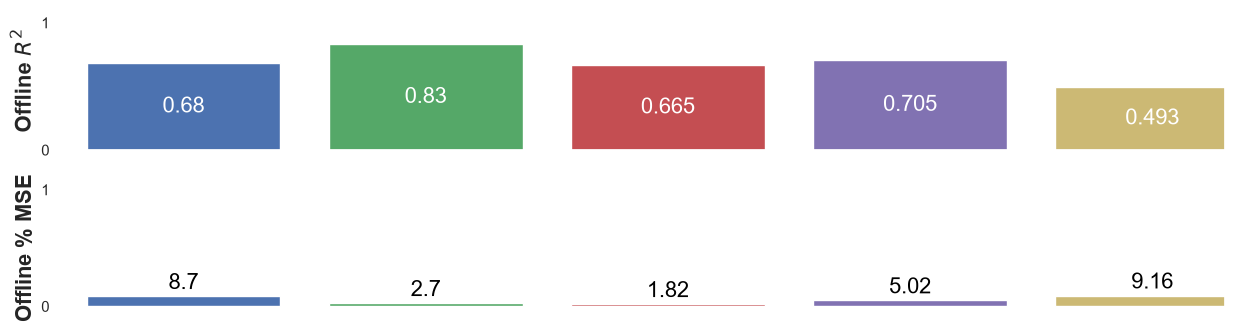

In [26]:
# cached results for consistency in the figure
offline_r2 = [0.68, 0.83, 0.665, 0.705, 0.493]
offline_mse = np.asarray([0.087, 0.027, 0.0182, 0.0502, 0.0916] )
participants = [1,2,3,4,5]
color_set =  ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974']


fig,ax = plt.subplots(2,1, figsize = (15,4))

ax0_bars = ax[0].bar(participants,offline_r2, color=color_set)

for bar in ax0_bars:
    height = bar.get_height()
    ax[0].text(
        bar.get_x() + bar.get_width() / 2,
        height / 2,                  # inside the bar
        f'{height}',
        ha='center',
        va='center',
        color='white',
        fontsize=16
    )


ax[0].set_xticks([1,2,3,4,5] )
ax[0].set_xticks([])
ax[0].set_ylim(0,1.1)
ax[0].set_yticks([0,0.25, 0.5, 0.75, 1])
ax[0].set_yticklabels(["0","", "", "", "1"])
ax[0].set_ylabel(r'Offline $R^2$',fontsize=16, weight="bold")
ax[0].set_xlim([0.5,5.3] )
ax[0].grid(False)

#-------------------------------------
ax1_bars = ax[1].bar(participants,offline_mse, color=color_set)

for bar in ax1_bars:
    height = bar.get_height()
    ax[1].text(
        bar.get_x() + bar.get_width() / 2,
        height+0.2,                  # inside the bar
        f'{np.round(100*height, 3)}',
        ha='center',
        va='top',
        color='black',
        fontsize=16
    )



ax[1].set_xticks([1,2,3,4,5] )
ax[1].set_xticks([])
ax[1].set_ylim(-0.1,1.1)
ax[1].set_yticks([0,0.25, 0.5, 0.75, 1])
ax[1].set_yticklabels(["0","", "", "", "1"])
ax[1].set_ylabel(r"Offline % MSE", fontsize=16, weight='bold')
ax[1].set_xlim([0.5,5.3] )
ax[1].grid(False)
